In [ ]:
import pandas as pd
df=pd.read_csv("Walmart_sales_analysis.csv")
df.head()

,Store_Number,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2/5/2010,"1,643,691",0,42.31,2.572,211,8.106
1,1,2/12/2010,"1,641,957",1,38.51,2.548,211,8.106
2,1,2/19/2010,"1,611,968",0,39.93,2.514,211,8.106
3,1,2/26/2010,"1,409,728",0,46.63,2.561,211,8.106
4,1,3/5/2010,"1,554,807",0,46.50,2.625,211,8.106


In [ ]:
df.shape

(6435, 8)

In [ ]:
df.dtypes

,0
Store_Number,int64
Date,object
Weekly_Sales,object
Holiday_Flag,int64
Temperature,float64
Fuel_Price,float64
CPI,int64
Unemployment,float64


In [ ]:
df['Weekly_Sales'] = df['Weekly_Sales'].str.replace(',', '').astype(int)

In [ ]:
df['Weekly_Sales'] = df['Weekly_Sales'].astype(int)

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])

In [ ]:
df.dtypes

,0
Store_Number,int64
Date,datetime64[ns]
Weekly_Sales,int64
Holiday_Flag,int64
Temperature,float64
Fuel_Price,float64
CPI,int64
Unemployment,float64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store_Number  6435 non-null   int64         
 1   Date          6435 non-null   datetime64[ns]
 2   Weekly_Sales  6435 non-null   int64         
 3   Holiday_Flag  6435 non-null   int64         
 4   Temperature   6435 non-null   float64       
 5   Fuel_Price    6435 non-null   float64       
 6    CPI          6435 non-null   int64         
 7   Unemployment  6435 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(4)
memory usage: 402.3 KB


In [ ]:
print(df['Weekly_Sales'].head(10))
print(df['Weekly_Sales'].isnull().sum())

0    1643691
1    1641957
2    1611968
3    1409728
4    1554807
5    1439542
6    1472516
7    1404430
8    1594968
9    1545419
Name: Weekly_Sales, dtype: int64
0


In [ ]:
df.columns

Index(['Store_Number', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
       'Fuel_Price', ' CPI ', 'Unemployment'],
      dtype='object')

In [ ]:
df.columns = df.columns.str.strip()

In [ ]:
df.columns

Index(['Store_Number', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
       'Fuel_Price', 'CPI', 'Unemployment'],
      dtype='object')

In [ ]:
df.describe()

,Store_Number,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6435,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,2011-06-17 00:00:00,1.046965e+06,0.069930,60.663782,3.358607,171.583994,7.999151
min,1.000000,2010-02-05 00:00:00,2.099860e+05,0.000000,-2.060000,2.472000,126.000000,3.879000
25%,12.000000,2010-10-08 00:00:00,5.533500e+05,0.000000,47.460000,2.933000,132.000000,6.891000
50%,23.000000,2011-06-17 00:00:00,9.607460e+05,0.000000,62.670000,3.445000,183.000000,7.874000
75%,34.000000,2012-02-24 00:00:00,1.420158e+06,0.000000,74.940000,3.735000,213.000000,8.622000
max,45.000000,2012-10-26 00:00:00,3.818686e+06,1.000000,100.140000,4.468000,227.000000,14.313000
std,12.988182,NaN,5.643666e+05,0.255049,18.444933,0.459020,39.351305,1.875885


In [ ]:
df.isnull().sum()

,0
Store_Number,0
Date,0
Weekly_Sales,0
Holiday_Flag,0
Temperature,0
Fuel_Price,0
CPI,0
Unemployment,0


In [ ]:
df.duplicated().sum()

np.int64(0)

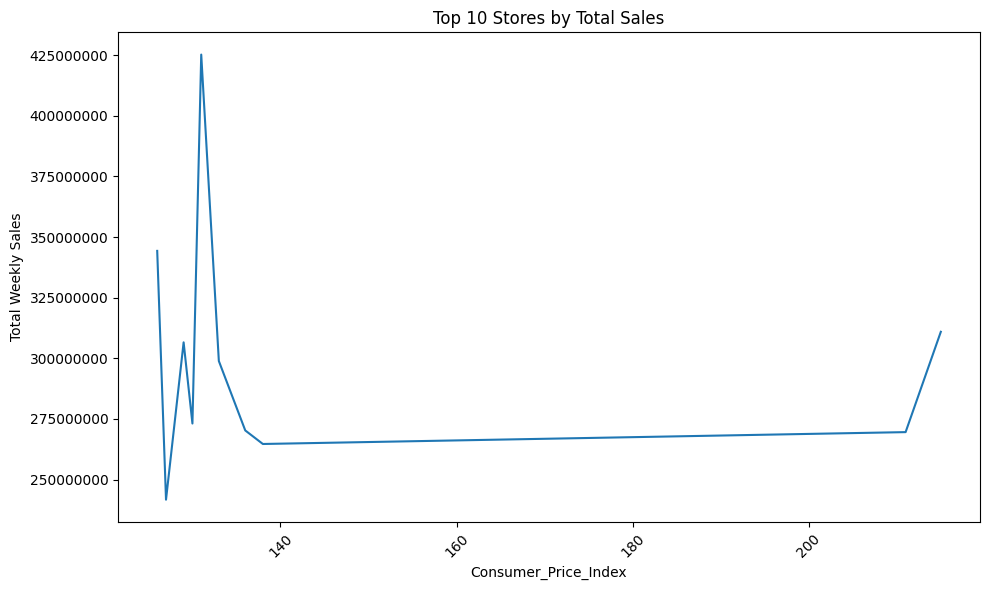

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

store_sales = df.groupby('CPI')['Weekly_Sales'].sum()

top_10_stores = (
    store_sales.sort_values(ascending=False)
    .head(10)
    .round(2)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.lineplot(data=top_10_stores, x='CPI', y='Weekly_Sales')

plt.title('Top 10 Stores by Total Sales')
plt.xlabel('Consumer_Price_Index')
plt.ylabel('Total Weekly Sales')

plt.xticks(rotation=45)
plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.show()

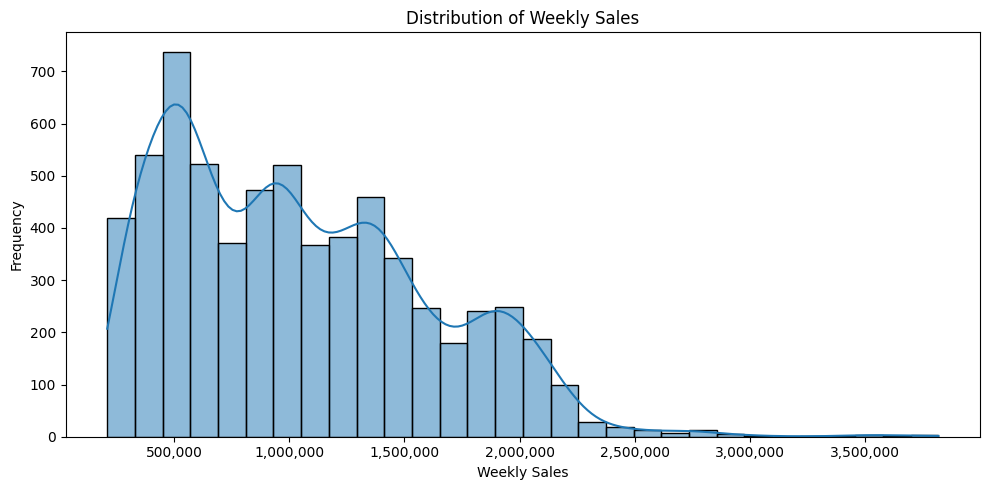

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='Weekly_Sales', bins=30, kde=True)

plt.title('Distribution of Weekly Sales')
plt.xlabel('Weekly Sales')
plt.ylabel('Frequency')

# Display full numbers on the X-axis
plt.gca().xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
plt.show()

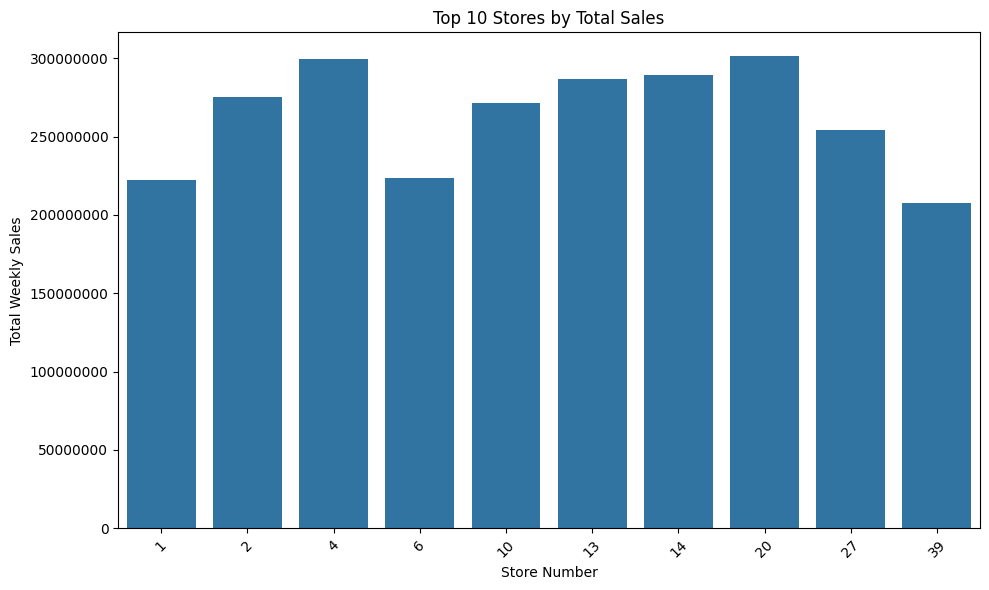

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

store_sales = df.groupby('Store_Number')['Weekly_Sales'].sum()

top_10_stores = (
    store_sales.sort_values(ascending=False)
    .head(10)
    .round(2)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(data=top_10_stores, x='Store_Number', y='Weekly_Sales')

plt.title('Top 10 Stores by Total Sales')
plt.xlabel('Store Number')
plt.ylabel('Total Weekly Sales')

plt.xticks(rotation=45)
plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.show()

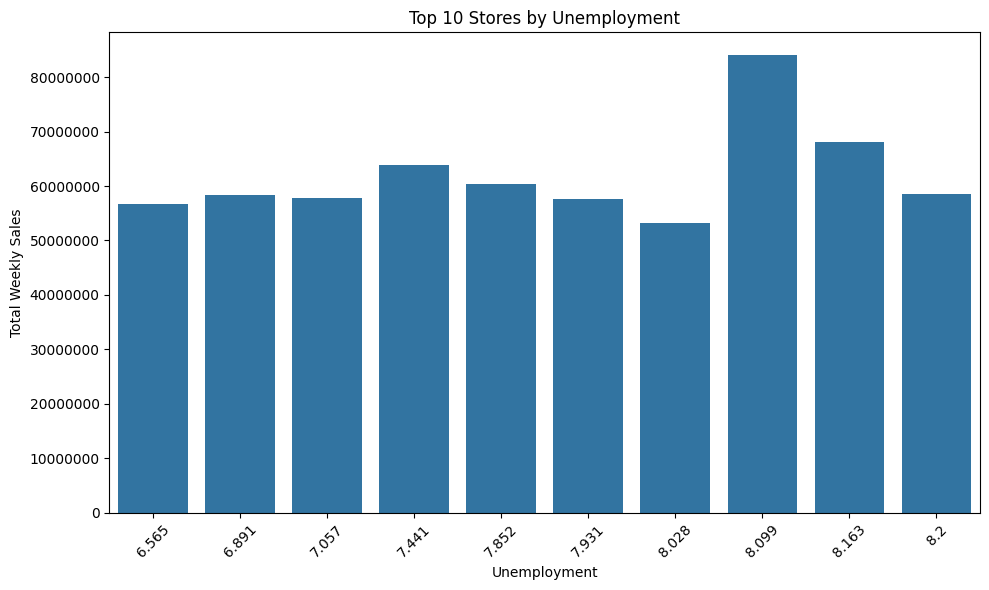

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

store_sales = df.groupby('Unemployment')['Weekly_Sales'].sum()

top_10_stores = (
    store_sales.sort_values(ascending=False)
    .head(10)
    .round(2)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(data=top_10_stores, x='Unemployment', y='Weekly_Sales')

plt.title('Top 10 Stores by Unemployment')
plt.xlabel('Unemployment')
plt.ylabel('Total Weekly Sales')

plt.xticks(rotation=45)
plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.show()

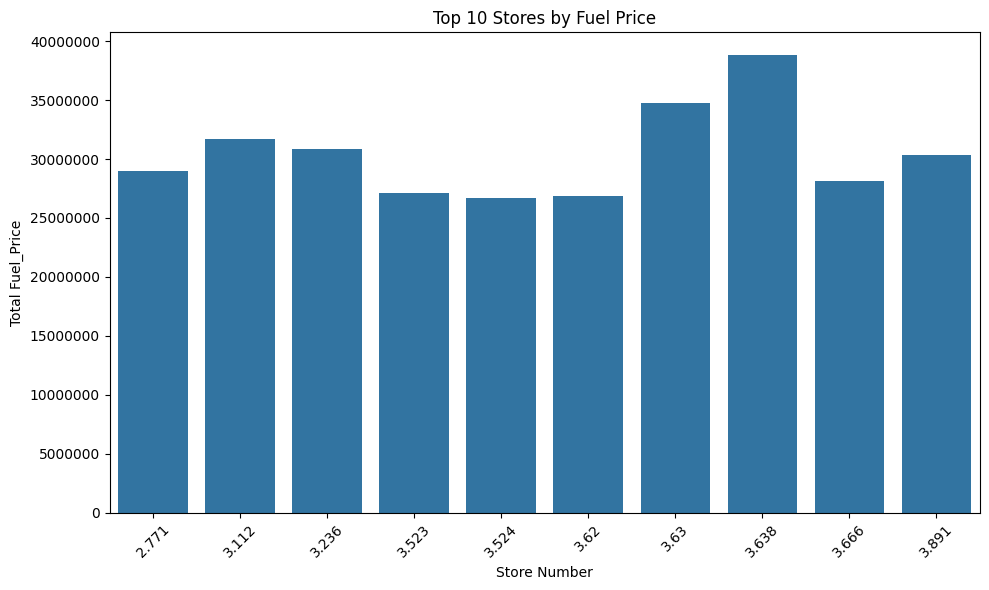

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

store_sales = df.groupby('Fuel_Price')['Weekly_Sales'].sum()

top_10_stores = (
    store_sales.sort_values(ascending=False)
    .head(10)
    .round(2)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(data=top_10_stores, x='Fuel_Price', y='Weekly_Sales')

plt.title('Top 10 Stores by Fuel Price')
plt.xlabel('Store Number')
plt.ylabel('Total Fuel_Price')

plt.xticks(rotation=45)
plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.show()

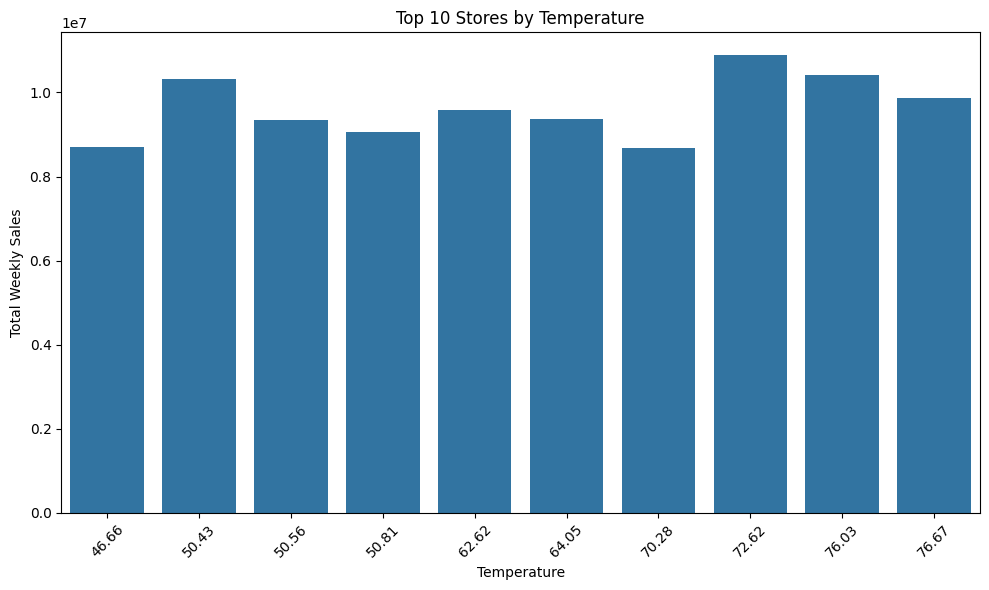

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

store_sales = df.groupby('Temperature')['Weekly_Sales'].sum()

top_10_stores = (
    store_sales.sort_values(ascending=False)
    .head(10)
    .round(2)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(data=top_10_stores, x='Temperature', y='Weekly_Sales')

plt.title('Top 10 Stores by Temperature')
plt.xlabel('Temperature')
plt.ylabel('Total Weekly Sales')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
df.columns

Index(['Store_Number', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
       'Fuel_Price', 'CPI', 'Unemployment'],
      dtype='object')

Month
January      332598442
February     568727899
March        592785890
April        646859784
May          557125577
June         622629888
July         650000982
August       613090214
September    578761186
October      584784778
November     413015735
December     576838633
Name: Weekly_Sales, dtype: int64


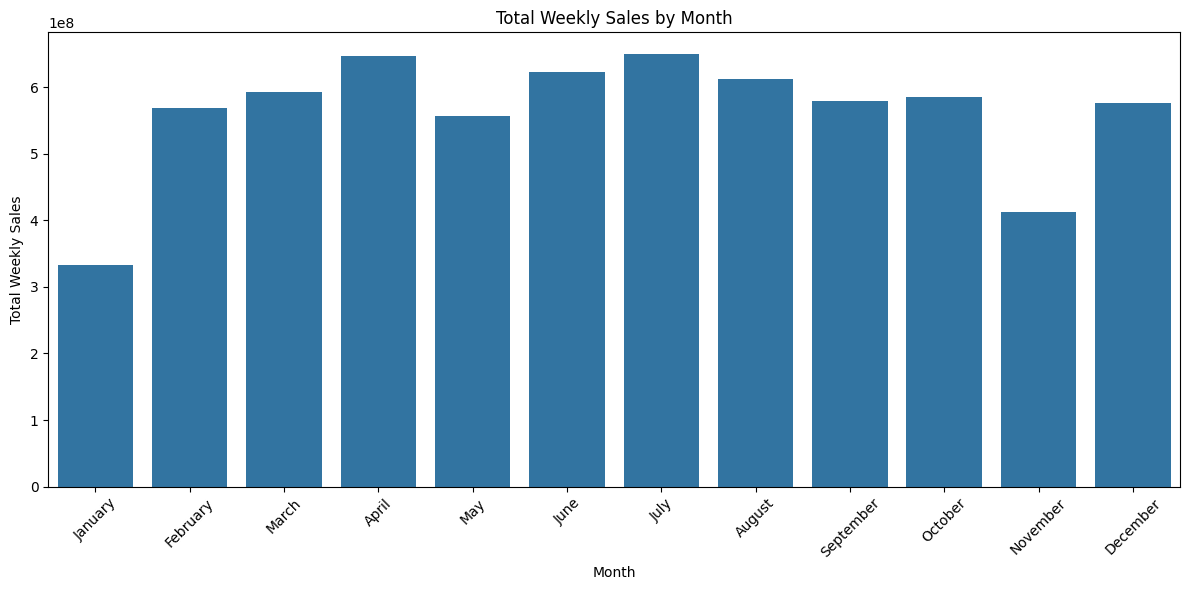

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Extract month name
df['Month'] = df['Date'].dt.month_name()

# Calculate total weekly sales for each month
monthly_sales = df.groupby('Month')['Weekly_Sales'].sum()

# Arrange months in calendar order
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_sales = monthly_sales.reindex(month_order).dropna()

# Display results
print(monthly_sales.round(2))

# Visualize monthly sales
plt.figure(figsize=(12, 6))
sns.barplot(x=monthly_sales.index, y=monthly_sales.values)

plt.title('Total Weekly Sales by Month')
plt.xlabel('Month')
plt.ylabel('Total Weekly Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

   Year  Weekly_Sales
0  2010    2288886130
1  2011    2448200019
2  2012    2000132859


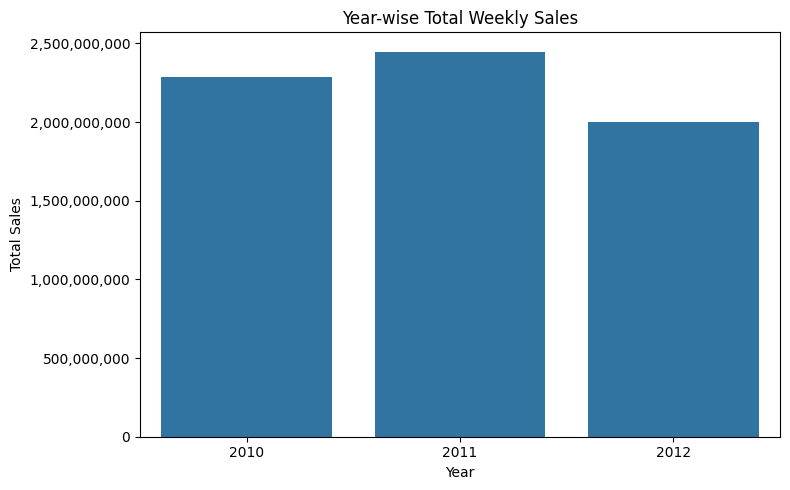

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter

# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Extract year
df['Year'] = df['Date'].dt.year

# Calculate total sales for each year
yearly_sales = df.groupby('Year')['Weekly_Sales'].sum().reset_index()

# Display results
print(yearly_sales)

# Create bar chart
plt.figure(figsize=(8, 5))

sns.barplot(data=yearly_sales, x='Year', y='Weekly_Sales')

plt.title('Year-wise Total Weekly Sales')
plt.xlabel('Year')
plt.ylabel('Total Sales')

# Display full numbers on Y-axis
plt.gca().yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

plt.tight_layout()
plt.show()

          Date  Weekly_Sales
46  2010-12-24      80931414
98  2011-12-23      76998240
94  2011-11-25      66593604
42  2010-11-26      65821006
45  2010-12-17      61820797
97  2011-12-16      60085697
44  2010-12-10      55666771
96  2011-12-09      55561146
113 2012-04-06      53502316
126 2012-07-06      51253023


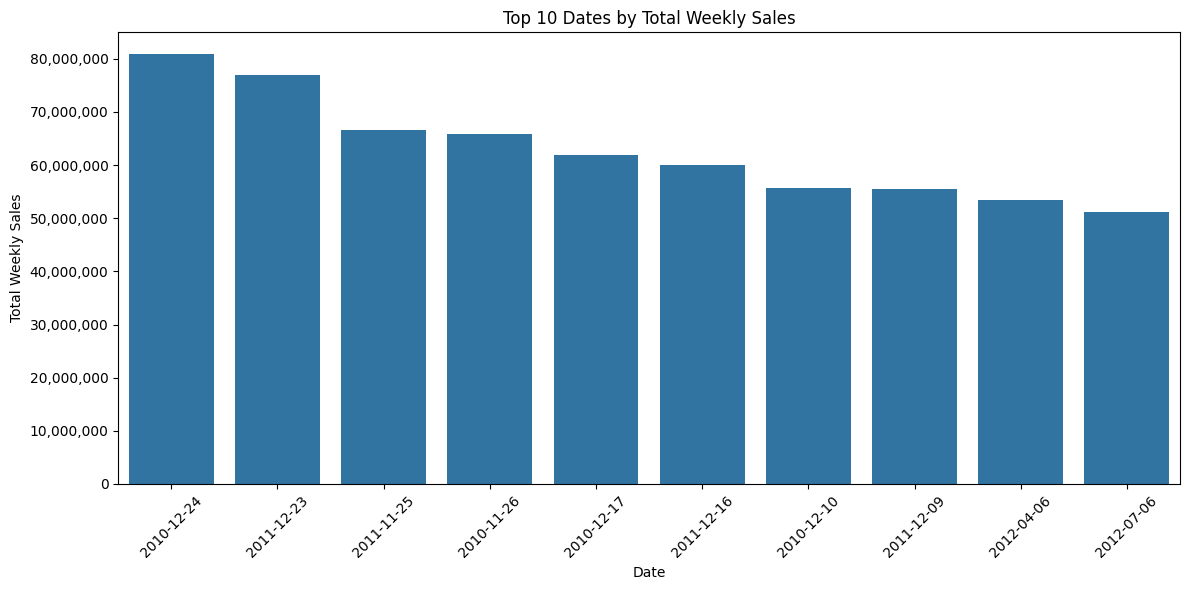

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter

# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Calculate total sales for each date across all stores
date_sales = df.groupby('Date')['Weekly_Sales'].sum().reset_index()

# Select top 10 dates by sales
top_10_dates = date_sales.nlargest(10, 'Weekly_Sales')

# Display results
print(top_10_dates)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_dates,
    x='Date',
    y='Weekly_Sales'
)

plt.title('Top 10 Dates by Total Weekly Sales')
plt.xlabel('Date')
plt.ylabel('Total Weekly Sales')

# Display full numbers on Y-axis
plt.gca().yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

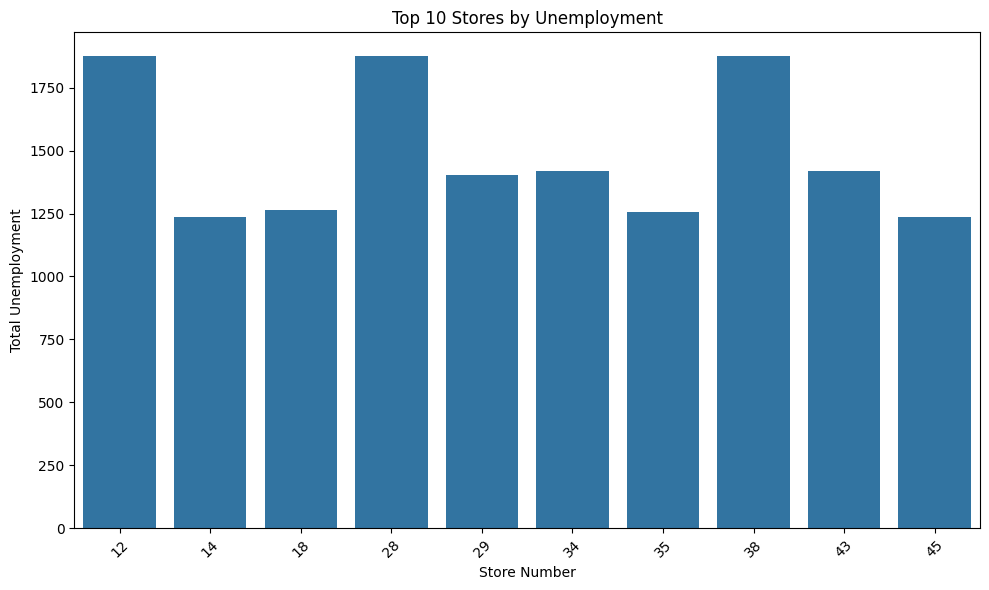

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

store_sales = df.groupby('Store_Number')['Unemployment'].sum()

top_10_stores = (
    store_sales.sort_values(ascending=False)
    .head(10)
    .round(2)
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(data=top_10_stores, x='Store_Number', y='Unemployment')

plt.title('Top 10 Stores by Unemployment')
plt.xlabel('Store Number')
plt.ylabel('Total Unemployment')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

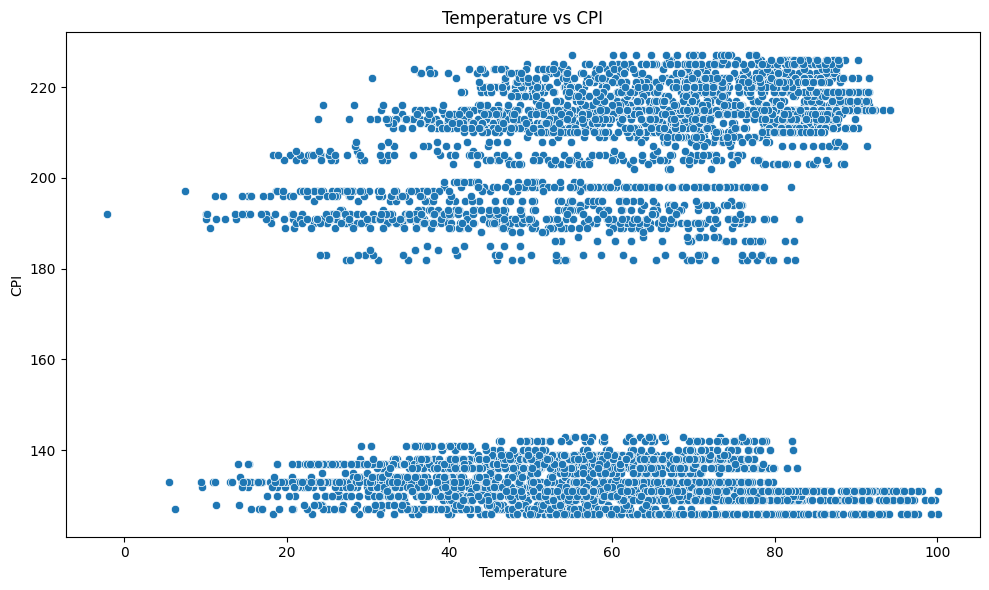

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='Temperature', y='CPI')

plt.title('Temperature vs CPI')
plt.xlabel('Temperature')
plt.ylabel('CPI')

plt.tight_layout()
plt.show()

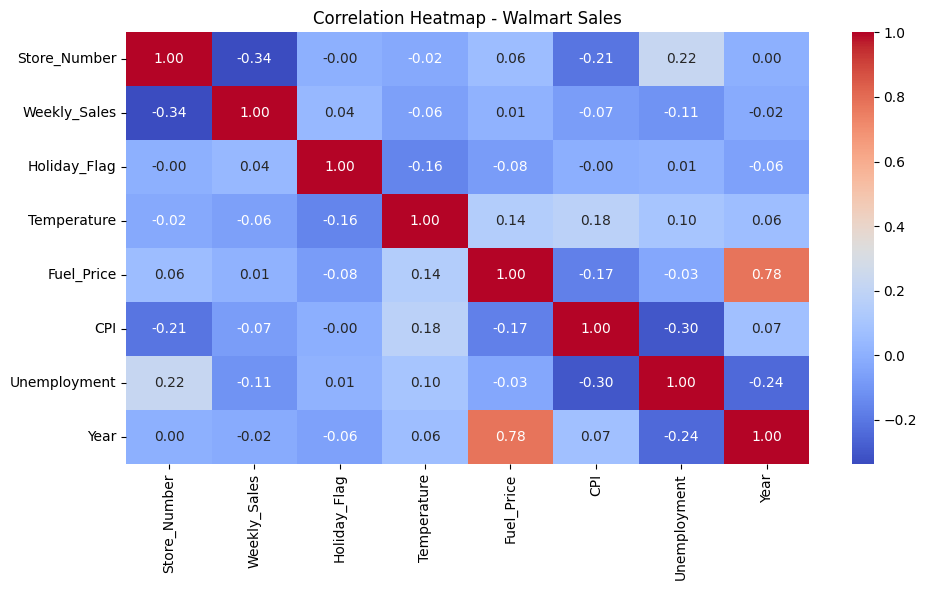

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation between numerical columns
correlation = df.select_dtypes(include='number').corr()

# Create heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap - Walmart Sales')
plt.tight_layout()
plt.show()

In [ ]:
df = df.drop('Date', axis=1)

In [ ]:
df.to_csv('Cleaned_Walmart_sales_analysis.csv', index=False)
print("Downloaded Successfully")

Downloaded Successfully
